In [10]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
r = requests.get(
    "https://mygene.info/v3/query",
    params={
        "q": "opsin",
        "species": "45351",
        "fields": "symbol,name,genomic_pos",
        "size": 50,
    },
)
data = r.json()
for x in data["hits"]:
    print(x["symbol"], "/", x["name"], "/", "position on genome is:", "genomic_pos" in x)

LOC5519253 / opsin-VA / position on genome is: False
LOC116614821 / blue-sensitive opsin / position on genome is: False
LOC5522135 / blue-sensitive opsin / position on genome is: False
LOC116617585 / ultraviolet-sensitive opsin / position on genome is: False
LOC5513830 / green-sensitive opsin-1 / position on genome is: False


In [12]:
for h in data["hits"]:
    gene = requests.get(
        f"https://mygene.info/v3/gene/{h['_id']}",
        params={"fields": "all"},
    ).json()
    print(h["symbol"], "->", list(gene.keys()))

LOC5519253 -> ['_id', '_version', 'accession', 'entrezgene', 'go', 'locus_tag', 'name', 'other_names', 'refseq', 'symbol', 'taxid', 'type_of_gene']
LOC116614821 -> ['_id', '_version', 'accession', 'entrezgene', 'go', 'name', 'other_names', 'refseq', 'symbol', 'taxid', 'type_of_gene']
LOC5522135 -> ['_id', '_version', 'accession', 'entrezgene', 'go', 'locus_tag', 'name', 'other_names', 'refseq', 'symbol', 'taxid', 'type_of_gene']
LOC116617585 -> ['_id', '_version', 'accession', 'alias', 'entrezgene', 'go', 'name', 'other_names', 'refseq', 'symbol', 'taxid', 'type_of_gene']
LOC5513830 -> ['_id', '_version', 'accession', 'alias', 'entrezgene', 'go', 'locus_tag', 'name', 'other_names', 'refseq', 'symbol', 'taxid', 'type_of_gene']


In [13]:
rows = []
for h in data["hits"]:
    gene = requests.get(f"https://mygene.info/v3/gene/{h['_id']}").json()
    proteins = gene["refseq"]["protein"]
    if isinstance(proteins, str):   # only one protein: wrap it into a list
        proteins = [proteins]
    rows.append({
        "symbol": gene["symbol"],
        "name": gene["name"],
        "protein counts": len(proteins),
        "protein_ids": ", ".join(proteins),
    })

df = pd.DataFrame(rows)
df.to_csv("nematostella_opsins.csv", index=False)
df

,symbol,name,protein counts,protein_ids
0,LOC5519253,opsin-VA,1,XP_048589374.1
1,LOC116614821,blue-sensitive opsin,1,XP_032232173.2
2,LOC5522135,blue-sensitive opsin,2,"XP_032223482.2, XP_048581596.1"
3,LOC116617585,ultraviolet-sensitive opsin,2,"XP_032236301.2, XP_032236303.2"
4,LOC5513830,green-sensitive opsin-1,1,XP_032239260.2


In [17]:
x = df.plot.bar(x="symbol", y="n_proteins", legend=False, figsize=(8, 4))
ax.set_ylabel("Number of RefSeq proteins")
ax.set_xlabel("")
ax.set_title("RefSeq protein records per Nematostella opsin gene")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("opsin_protein_counts.png")
plt.show()

KeyError: 'n_proteins'

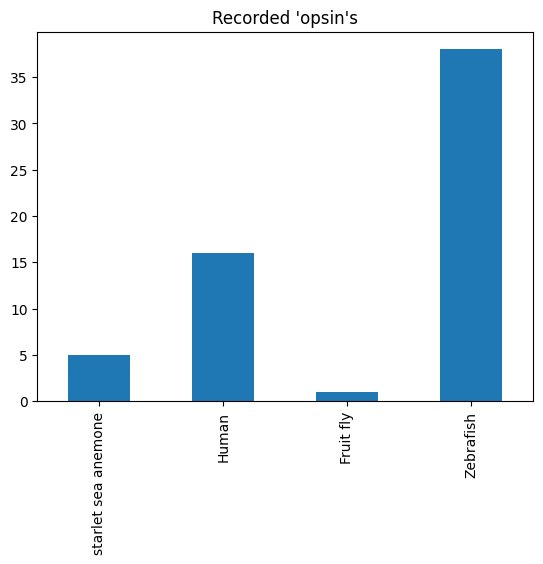

In [16]:
species = {"starlet sea anemone": 45351, "Human": 9606, "Fruit fly": 7227, "Zebrafish": 7955}
counts = {}

for name, taxid in species.items():
    r = requests.get("https://mygene.info/v3/query", params={"q": "opsin", "species": taxid})
    counts[name] = r.json()["total"]

pd.Series(counts).plot.bar(title="Recorded 'opsin's")
plt.savefig("opsin_by_species.png")